# Parte 4 — Robustez y counterfactuals

**Objetivo:** un modelo puede tener buen Gini y aun así ser frágil o dar respuestas absurdas.
Esta notebook revisa tres cosas:

1. **Consistencia:** ¿cambia la decisión ante un ruido chico (±5%) en los datos de entrada?
2. **Monotonía del monto:** ¿pedir más plata baja la PD? No debería.
3. **Counterfactual accionable:** para un rechazado, ¿qué monto sí se le podría aprobar?

Las perturbaciones se aplican sobre las **variables crudas**, y los ratios se recalculan
(`PDScorer.pd_from_raw`). La versión anterior perturbaba las features ya estandarizadas e
incluso las columnas one-hot, lo que no representa ningún cambio realista en un cliente.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import reference_cutoff
from src.models.pd_model import PDScorer

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
rng = np.random.default_rng(42)

CUTOFF   = reference_cutoff()
scorer   = PDScorer()
raw_test = pd.read_parquet('data/processed/test.parquet')
sample   = raw_test.sample(3000, random_state=42).reset_index(drop=True)
pd_base  = scorer.pd_from_raw(sample)
print(f'Cutoff PD: {CUTOFF:.1%} | muestra: {len(sample):,} | rechazados: {(pd_base >= CUTOFF).mean():.1%}')

Cutoff PD: 20.3% | muestra: 3,000 | rechazados: 6.9%


## 4.1 Test de consistencia — ruido de ±5% en variables continuas

Se perturban montos, ingresos, antigüedades y scores de bureau, como si fueran errores de
carga o de redondeo. No se tocan los conteos ni las categorías.

In [2]:
CONTINUAS = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
             'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
             'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']

def perturbar(df, pct=0.05):
    out = df.copy()
    for c in CONTINUAS:
        out[c] = out[c] * (1 + rng.uniform(-pct, pct, len(out)))
    out['EXT_SOURCE_1'] = out['EXT_SOURCE_1'].clip(0, 1)
    out['EXT_SOURCE_2'] = out['EXT_SOURCE_2'].clip(0, 1)
    out['EXT_SOURCE_3'] = out['EXT_SOURCE_3'].clip(0, 1)
    return out

pd_pert = scorer.pd_from_raw(perturbar(sample))
cons = pd.DataFrame({'pd': pd_base, 'pd_pert': pd_pert})
cons['delta_abs'] = (cons['pd_pert'] - cons['pd']).abs()
cons['delta_rel'] = cons['delta_abs'] / cons['pd']
cons['flip'] = (cons['pd'] >= CUTOFF) != (cons['pd_pert'] >= CUTOFF)
cons['cerca_cutoff'] = (cons['pd'] - CUTOFF).abs() < 0.03

print(f'|ΔPD| medio: {cons["delta_abs"].mean():.4f} | p95: {cons["delta_abs"].quantile(0.95):.4f}')
print(f'ΔPD relativo mediano: {cons["delta_rel"].median():.1%}')
print(f'Decisión cambia: {cons["flip"].mean():.1%} del total')
print(f'  - entre los que están a menos de 3 pp del cutoff: {cons.loc[cons.cerca_cutoff, "flip"].mean():.1%} '
      f'({cons.cerca_cutoff.mean():.1%} de la muestra)')
print(f'  - entre los que están lejos del cutoff:           {cons.loc[~cons.cerca_cutoff, "flip"].mean():.1%}')

|ΔPD| medio: 0.0098 | p95: 0.0349
ΔPD relativo mediano: 9.7%
Decisión cambia: 2.0% del total
  - entre los que están a menos de 3 pp del cutoff: 27.2% (5.0% de la muestra)
  - entre los que están lejos del cutoff:           0.6%


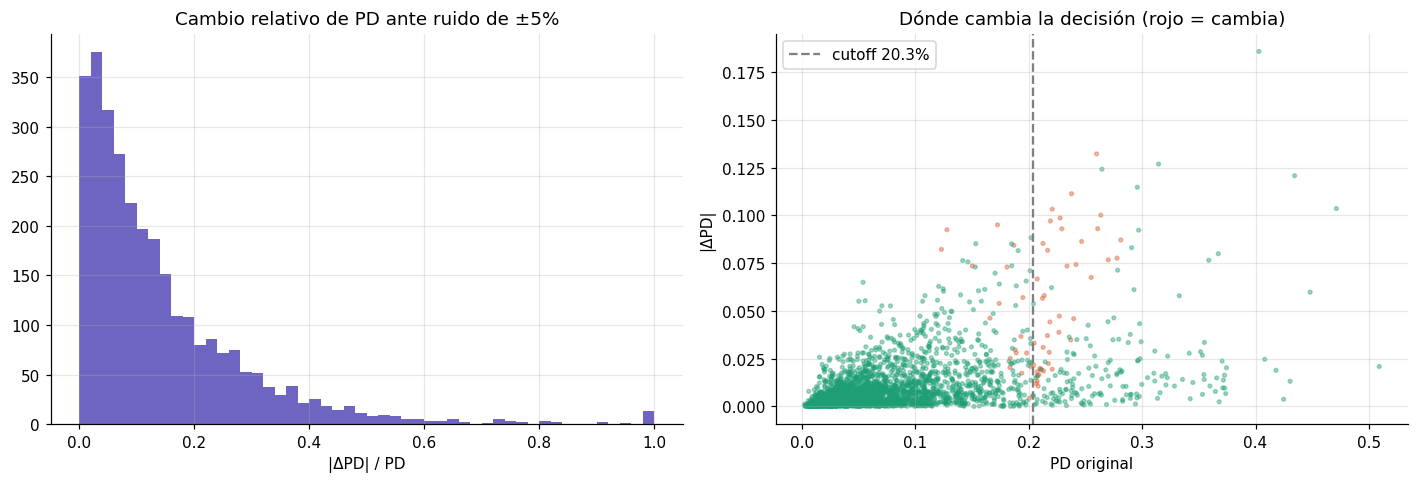

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(cons['delta_rel'].clip(upper=1), bins=50, color='#534AB7', alpha=0.85)
axes[0].set_title('Cambio relativo de PD ante ruido de ±5%'); axes[0].set_xlabel('|ΔPD| / PD')
axes[1].scatter(cons['pd'], cons['delta_abs'], s=6, alpha=0.4,
                c=np.where(cons['flip'], '#D85A30', '#1D9E75'))
axes[1].axvline(CUTOFF, color='gray', ls='--', label=f'cutoff {CUTOFF:.1%}')
axes[1].set_xlabel('PD original'); axes[1].set_ylabel('|ΔPD|')
axes[1].set_title('Dónde cambia la decisión (rojo = cambia)'); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('reports/figures/consistency_test.png', dpi=150, bbox_inches='tight'); plt.show()

### Consistencia

**El modelo es estable frente a ruido chico.** Con ±5% en las variables continuas:
- el cambio absoluto medio de PD es 1,0 pp (p95: 3,5 pp);
- la decisión cambia en el 2,0% de los casos.

**La inestabilidad está donde tiene que estar.** Entre los clientes a menos de 3 pp del
cutoff (el 5% de la muestra), la decisión cambia en el 27% de los casos. Lejos del cutoff
cambia en el 0,6%. Es lo esperable en cualquier regla con corte duro.

**Implicancia.** Una banda de revisión manual de ±3 pp alrededor del cutoff cubriría el 5%
de las solicitudes y concentraría la mayoría de las decisiones frágiles. Es una carga
operativa razonable.

## 4.2 Monotonía respecto del monto solicitado

A igualdad de todo lo demás, pedir más plata (con la cuota y el valor del bien
proporcionales) no debería **bajar** la PD. Se escala el monto entre 50% y 200% para cada
cliente y se mide cuántos tienen una relación inversa.

Clientes donde la PD BAJA al pedir más monto: 35.7%
PD media al 50% del monto: 6.49% | al 100%: 7.65% | al 200%: 7.67%


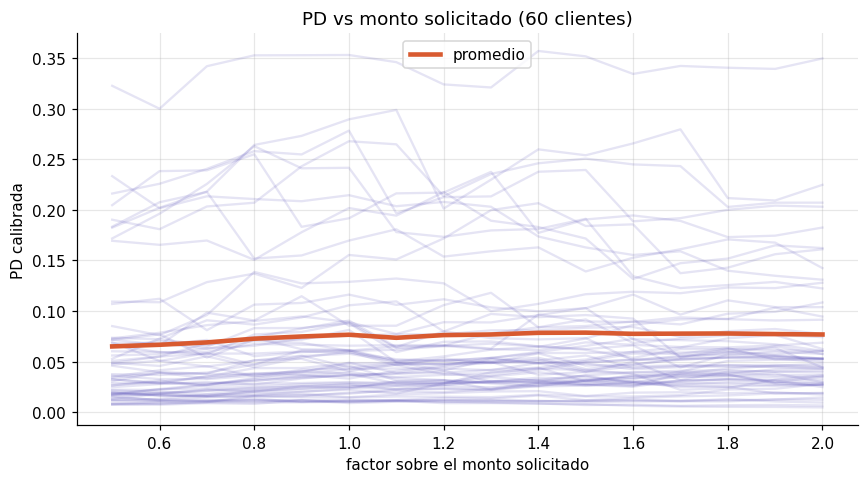

In [4]:
factores = np.round(np.arange(0.5, 2.01, 0.1), 2)
sub = sample.sample(1000, random_state=1).reset_index(drop=True)
curvas = []
for f in factores:
    d = sub.copy()
    for c in ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']:
        d[c] = d[c] * f
    curvas.append(scorer.pd_from_raw(d))
curvas = np.vstack(curvas).T          # clientes x factores

pendiente = np.array([np.polyfit(factores, c, 1)[0] for c in curvas])
print(f'Clientes donde la PD BAJA al pedir más monto: {(pendiente < 0).mean():.1%}')
print(f'PD media al 50% del monto: {curvas[:, 0].mean():.2%} | al 100%: {curvas[:, 5].mean():.2%} '
      f'| al 200%: {curvas[:, -1].mean():.2%}')

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in curvas[:60]:
    ax.plot(factores, c, color='#534AB7', alpha=0.15)
ax.plot(factores, curvas.mean(axis=0), color='#D85A30', lw=3, label='promedio')
ax.set_xlabel('factor sobre el monto solicitado'); ax.set_ylabel('PD calibrada')
ax.set_title('PD vs monto solicitado (60 clientes)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Monotonía

**Hallazgo: la PD no es monótona respecto del monto.**
- En el **35,7%** de los clientes, pedir más monto (con la cuota y el valor del bien
  proporcionales) **baja** la PD.
- En promedio, la PD sube de 6,5% a 7,7% al pasar del 50% al 100% del monto, y después queda
  plana hasta el 200%.

Esto explica el resultado de la versión anterior de esta notebook, donde el counterfactual
pedía *subir* el crédito un 45–60% para aprobar. No es un artefacto del método: el modelo
aprendió relaciones del tipo "créditos más grandes → clientes con más respaldo". Eso es
correlación de selección (a quien pide más se lo filtró más antes), no causalidad.

**Por qué importa.**
- Un modelo así se puede "jugar": pidiendo más plata se mejora la evaluación.
- Es difícil de justificar ante un regulador o un cliente.

**Recomendación (challenger a evaluar):**
- XGBoost con `monotone_constraints` en AMT_CREDIT, AMT_ANNUITY y los ratios cuota/ingreso y
  crédito/ingreso;
- medir cuánto Gini cuesta la restricción.

Queda como observación abierta de la validación.

> **Seguimiento.** Resuelto en los challengers M1 y M3 (`src/models/challengers.py`,
> [ADR 0008](../docs/decisions/0008-challengers.md)). Con `monotone_constraints` y
> `credit_goods_ratio` en lugar de AMT_GOODS_PRICE en nivel, la violación baja de ~35% a **0%**.
> El costo es ~0,9 puntos de Gini sin variables de pagos, y ~0,5 con ellas.

## 4.3 Counterfactual accionable: monto máximo aprobable

Para cada rechazado se busca el mayor monto (entre 100% y 10% del pedido) con el que la PD
queda debajo del cutoff. Es la respuesta que un analista de crédito puede ofrecer:
"no a $X, sí a $Y".

In [5]:
rech = sample[pd_base >= CUTOFF].reset_index(drop=True)
grid = np.round(np.arange(1.0, 0.09, -0.05), 2)
pd_grid = []
for f in grid:
    d = rech.copy()
    for c in ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']:
        d[c] = d[c] * f
    pd_grid.append(scorer.pd_from_raw(d))
pd_grid = np.vstack(pd_grid).T        # rechazados x factores

aprobable = pd_grid < CUTOFF
max_factor = np.where(aprobable.any(axis=1), grid[np.argmax(aprobable, axis=1)], np.nan)
res = pd.Series(max_factor)
print(f'Rechazados en la muestra: {len(rech):,}')
print(f'  rescatables bajando el monto hasta un 50%: {(res >= 0.5).mean():.1%}')
print(f'  rescatables con cualquier reducción (hasta 10%): {res.notna().mean():.1%}')
print(f'  no rescatables por monto: {res.isna().mean():.1%}')
print()
print('Distribución del factor máximo aprobable (entre los rescatables):')
print(res.dropna().describe(percentiles=[.25, .5, .75]).round(2).to_string())

ejemplos = rech.assign(pd=pd_grid[:, 0], factor_max=max_factor)[
    ['AMT_CREDIT', 'AMT_INCOME_TOTAL', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'pd', 'factor_max']].head(8)
ejemplos['monto_max_aprobable'] = ejemplos['AMT_CREDIT'] * ejemplos['factor_max']
ejemplos.round(3)

Rechazados en la muestra: 207
  rescatables bajando el monto hasta un 50%: 58.0%
  rescatables con cualquier reducción (hasta 10%): 80.2%
  no rescatables por monto: 19.8%

Distribución del factor máximo aprobable (entre los rescatables):
count    166.00
mean       0.63
std        0.24
min        0.10
25%        0.45
50%        0.70
75%        0.85
max        0.95


,AMT_CREDIT,AMT_INCOME_TOTAL,EXT_SOURCE_2,EXT_SOURCE_3,pd,factor_max,monto_max_aprobable
0,195543.0,112500.0,0.254,NaN,0.226,0.80,156434.4
1,229500.0,99000.0,0.108,0.108,0.283,0.65,149175.0
2,450000.0,405000.0,0.264,0.158,0.279,NaN,NaN
3,629325.0,180000.0,0.263,0.090,0.310,NaN,NaN
4,329904.0,202500.0,0.323,0.338,0.269,0.55,181447.2
5,450000.0,225000.0,0.545,0.104,0.365,0.40,180000.0
6,755190.0,225000.0,0.003,NaN,0.434,NaN,NaN
7,323460.0,225000.0,0.296,0.209,0.207,0.85,274941.0


### Counterfactuals y veredicto de robustez

**Monto máximo aprobable.** Entre los 207 rechazados de la muestra:
- el **58%** se podría aprobar bajando el monto hasta la mitad;
- el **80%**, con alguna reducción;
- el factor mediano es 0,70 (es decir, aprobar el 70% de lo pedido).

El 20% restante no es rescatable por monto: su riesgo viene de bureau bajo o faltante, no
del tamaño del préstamo.

Es una salida comercial concreta, del tipo *"no a $450.000, sí a $180.000"*, y mejor que un
rechazo seco. Hay una salvedad: por la no-monotonía del punto 4.2, para algunos clientes
bajar el monto no baja la PD. Si se aplicara la restricción monotónica, este análisis sería
más confiable.

**Veredicto de robustez: APTO CON OBSERVACIONES.**
1. Es estable frente a ruido de carga.
2. Requiere una banda de revisión manual de ±3 pp alrededor del cutoff.
3. Queda abierta la no-monotonía respecto del monto, a resolver con un challenger
   monotónico antes de usar el modelo para ofrecer montos.